In [1]:
import eu9_osm
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from shapely.geometry import Polygon
from pyfonts import load_bunny_font
from matplotlib_map_utils.core.scale_bar import scale_bar

In [2]:
# Center for dist
lat = 38.71139
lon = -9.1375

# Roads
roads = eu9_osm.features_from_point(
       (lat, lon),
        tags={"highway": True},
        dist=1000,
        shape="box"
        )       

roads = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]

In [3]:
roads.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
# bbox to highlight streets
bbox_coords = [
    (-9.139556, 38.7129),    
    (-9.138218, 38.709349),  
    (-9.135593, 38.709943),  
    (-9.136999, 38.71345),  
]

bbox = Polygon(bbox_coords)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox], crs="EPSG:4326")

In [5]:
# Reproject 
roads_proj = roads.to_crs(epsg=3763)
bbox_proj = bbox_gdf.to_crs(epsg=3763)

In [6]:
# Clip roads
baixa_roads = gpd.clip(roads_proj, bbox_proj)
# Roads outside
roads_outside = roads_proj[~roads_proj.geometry.intersects(bbox_proj.geometry.iloc[0])].copy()

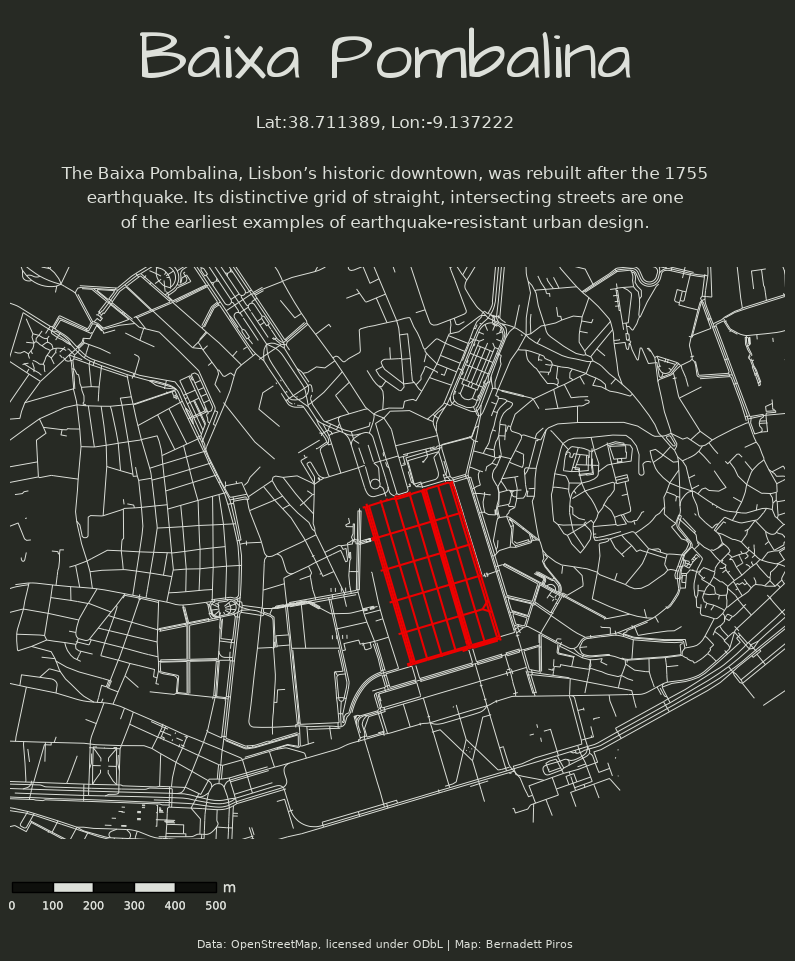

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#272a24")
    
roads_outside.plot(ax=ax, color="#dde0da", lw=0.7)

baixa_roads.plot(ax=ax, color="#ed0000", lw=1.5)

ax.set_xlim(-88400, -86500)
ax.set_ylim(-106400, -105000)

ax.set_facecolor("#272a24")

ax.axis("off")

# Scale bar
scale_bar(
    ax=ax,
    location="lower left",
    style="boxes",
    bar={
        "projection": 3763,
        "unit": "m",
        "max": 500,
        "major_div": 5,
        "minor_type": "none",
        "facecolors": ["#0e0f0c", "#dde0da"],
        "edgecolor": "#0e0f0c",
    },
    aob={
        "bbox_to_anchor": (-0.02, -0.15),
        "bbox_transform": ax.transAxes
    },
    labels={
        "style": "major",
        "loc": "below",
        "fontsize": 8,
        "pad": 0
    },
    units={
        "loc": "bar"
    },
    text={
        "textcolor": "#dde0da",
        "stroke_color": "#dde0da",
        "stroke_width": 0.1,
        "fontsize": 10
    }
)

title_font = load_bunny_font("Architects Daughter")

bplat = 38.711389
bplon = -9.137222

fig.text(0.5, 0.97, "Baixa Pombalina", size=50, color="#dde0da", weight="bold", font=title_font, ha="center")  
fig.text(0.5, 0.92, f"Lat:{bplat}, Lon:{bplon}", size=12, color="#dde0da", ha="center")

fig.text(
    0.5, 0.82,
    "The Baixa Pombalina, Lisbon’s historic downtown, was rebuilt after the 1755\n"
    "earthquake. Its distinctive grid of straight, intersecting streets are one\n"
    "of the earliest examples of earthquake-resistant urban design.",    
    fontsize=12,
    color="#dde0da",
    linespacing=1.5,
    ha="center"
)

fig.text(
    0.5, 0.1,    
    "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros",    
    fontsize=8,
    color="#dde0da",   
    ha="center"
)

plt.show()

#fig.savefig("baixa_pombalina.png", bbox_inches="tight", pad_inches=0.2) 